In [65]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

In [ ]:
from utils.telco_customer_churn import X_train, X_test, y_train, y_test, column_names
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

# What i learned:
i learned about hyperparameter `C` in scikit-learn's LogisticRegression. it a regularization hyperparameter.

In [76]:
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split 
from sklearn.model_selection import cross_validate

# X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

C_values = [0.1, 0.3, 0.5, 0.7, 1, 2, 5, 10, 100]

score_df = pd.DataFrame(columns=['f1', 'accuracy', 'roc_auc'], index=C_values)

for C in C_values:
  model = LogisticRegression(random_state=42, max_iter=1000, C=C)
  model.fit(X_train, y_train)

  cv = cross_validate(
    model, X_train, y_train,
    cv=5,
    scoring=['f1', 'accuracy', 'roc_auc'],
    return_train_score=False
  )
  score_df.loc[C, "f1"] = cv['test_f1'].mean()
  score_df.loc[C, "accuracy"] = cv['test_accuracy'].mean()
  score_df.loc[C, "roc_auc"] = cv['test_roc_auc'].mean()

score_df

,f1,accuracy,roc_auc
0.1,0.58133,0.799787,0.839694
0.3,0.586898,0.801207,0.840344
0.5,0.587507,0.801207,0.840495
0.7,0.588615,0.801384,0.840591
1.0,0.589522,0.801384,0.84071
2.0,0.591264,0.80174,0.840797
5.0,0.592215,0.802095,0.840912
10.0,0.590658,0.80103,0.840973
100.0,0.589881,0.800853,0.841022


## Interpretation of the results:
- this cross validation shows us that the best value for C is 1, which is the default value for C in LogisticRegression.
- This tells us in this dataset, C=1 sets a good balance between bias and variance.

In [67]:
weights = sorted(zip(column_names, model.coef_[0]), key=lambda x: x[1])
weights[0:3], weights[-3:]

([('onehot_drop__Contract_Two year', np.float64(-1.394054727543116)),
  ('standardize__tenure', np.float64(-1.3583310032014386)),
  ('onehot_no_drop__InternetService_No', np.float64(-1.054832026328549))],
 [('binary_addons__PaperlessBilling', np.float64(0.33361070340481064)),
  ('standardize__TotalCharges', np.float64(0.6546442438542639)),
  ('onehot_no_drop__InternetService_Fiber optic',
   np.float64(0.7000301388733484))])

## Feature Importance Analysis (Top 6 Logistic Regression Coefficients)

*Assuming target `Churn = 1`: **negative** coefficients indicate higher retention; **positive** coefficients indicate higher churn risk (holding other features constant).*

| Feature | Coef ($\beta$) | Effect on Churn | Interpretation |
| :--- | :---: | :---: | :--- |
| `Contract_Two year` | `-1.3` | **Strong Retention** | Strongest predictor of customer retention compared to shorter contracts. |
| `tenure` | `-1.33` | **Strong Retention** | Longer-tenured customers are much less likely to leave. |
| `InternetService_No` | `-0.90` | **Retention** | Phone-only customers (no internet service) tend to stay longer. |
| `InternetService_Fiber optic` | `+0.65` | **High Churn Risk** | Fiber optic users show the highest associated risk of churning. |
| `TotalCharges` | `+0.63` | **Churn Risk** | Higher total charges are associated with higher churn when holding `tenure` constant (likely reflecting higher monthly costs/multicollinearity). |
| `PaperlessBilling` | `+0.33` | **Moderate Churn Risk** | Customers using paperless billing churn more than those on paper bills. |

> **Note:** If numerical features (`tenure`, `TotalCharges`) were standardized while one-hot features remain `0/1`, raw coefficient magnitudes aren't strictly 1-to-1 comparable across both types—treat this ranking as directional intuition.

<Axes: >

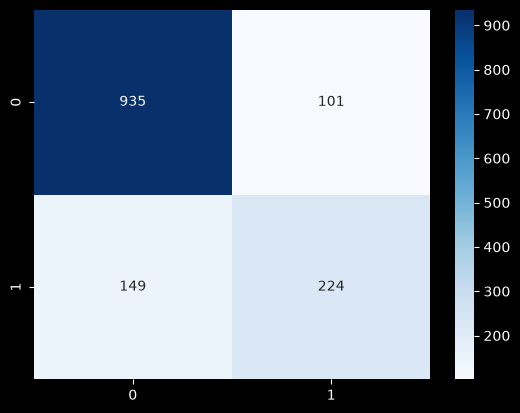

In [70]:
import seaborn as sns

confusion_mat = confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_mat, cmap='Blues', annot=True, fmt='d')

In [ ]:
#! Lets implement our own logistic regression model from scratch with numpy which match's sklearn's implementation.


from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np


class LogisticRegressionModel(BaseEstimator, ClassifierMixin):
  def __init__(self, learning_rate=0.1, n_iterations=1000):
    self.learning_rate=learning_rate
    self.n_iterations=n_iterations

  @staticmethod
  def _sigmoid(z):
    return 1 / (1 + np.exp(-z))

  def fit(self, X, y):
    n = X.shape[0]
    X = np.concat((np.ones((n, 1)), X), axis=1)
    y = np.asarray(y)

    B = np.zeros((X.shape[1]))

    for i in range(self.n_iterations):
      p = self._sigmoid(X@B)
      coefs = 1/n * X.T@(p - y)
      B -= self.learning_rate * coefs

    self.intercept_ = B[0]
    self.coef_ = B[1:]

  def predict(self, X):
    z = self.intercept_ + (X @ self.coef_)
    score = self._sigmoid(z)
    return (score >= 0.5).astype(int)



m = LogisticRegressionModel()
m.fit(X_train, y_train)

y_pred = m.predict(X_test)

print(classification_report(y_test, y_pred))
